<h1>Lab : Gaussian Mixture Models</h1>
Part 1

In [37]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
import numpy as np

In [ ]:
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=400, centers=4,
                       cluster_std=0.60, random_state=0)
X = X[:, ::-1] 

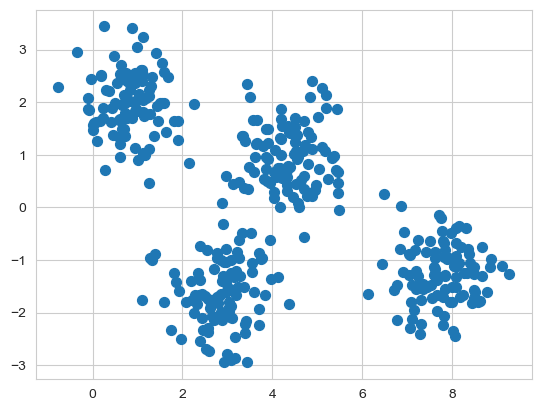

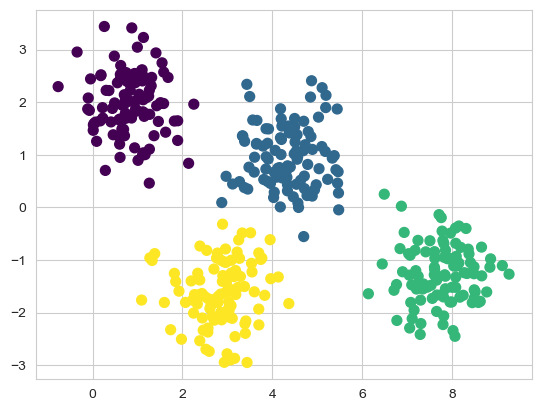

In [ ]:
from sklearn.cluster import KMeans
plt.scatter(X[:, 0], X[:, 1], s=50);
plt.show()
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_lmeans = kmeans.predict(X)
plt.scatter(X[:, 0], X[:, 1], c=y_lmeans, s=50, cmap='viridis');
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

def plot_kmeans(kmeans, X, n_clusters=4, rseed=0, ax=None):
    labels = kmeans.fit_predict(X)

    ax = ax or plt.gca()
    ax.axis('equal')
    ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis', zorder=2)

    centers = kmeans.cluster_centers_
    radii = [cdist(X[labels == i], [center]).max()
             for i, center in enumerate(centers)]
    for c, r in zip(centers, radii):
        ax.add_patch(plt.Circle(c, r, ec='black', fc='lightgray',
                                lw=3, alpha=0.5, zorder=1))

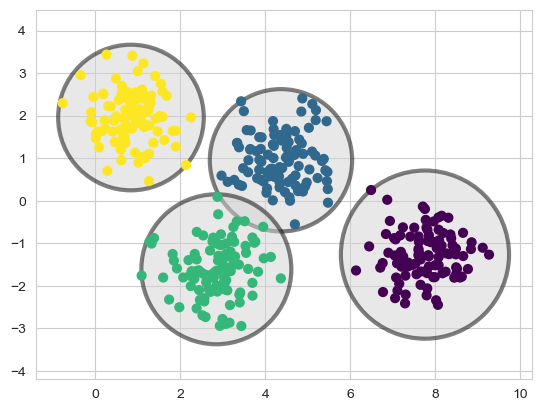

In [41]:
kmeans = KMeans(n_clusters=4, random_state=0)
plot_kmeans(kmeans, X)

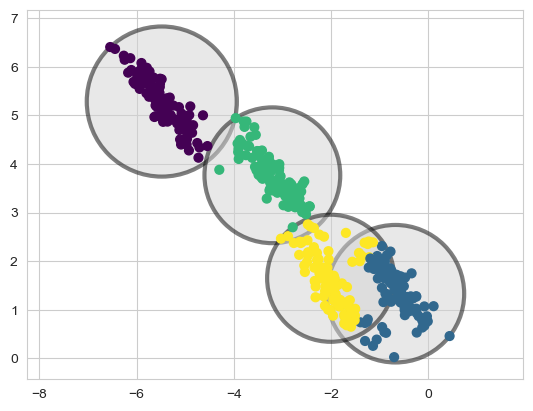

In [42]:
rng = np.random.RandomState(13)
X_stretched = np.dot(X, rng.randn(2, 2))

kmeans = KMeans(n_clusters=4, random_state=0)
plot_kmeans(kmeans, X_stretched)

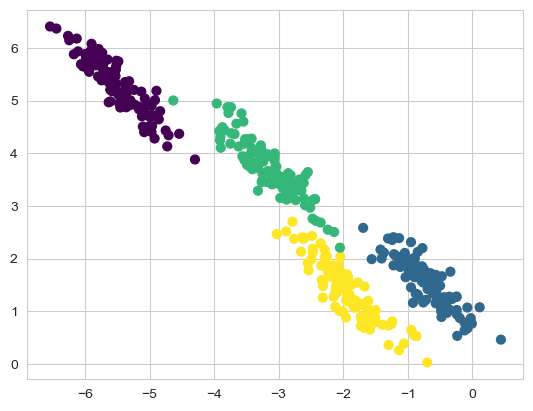

In [ ]:
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=4, random_state=0)
labels = gmm.fit_predict(X_stretched)
plt.scatter(X_stretched[:, 0], X_stretched[:, 1], c=labels, s=40, cmap='viridis');
plt.show()

In [ ]:
labels_proba = gmm.predict_proba(X_stretched)
print(labels_proba[:5].round(3))

[[0.426 0.    0.574 0.   ]
 [0.    0.    0.    1.   ]
 [0.    0.    0.    1.   ]
 [0.    0.    1.    0.   ]
 [0.    0.    0.    1.   ]]


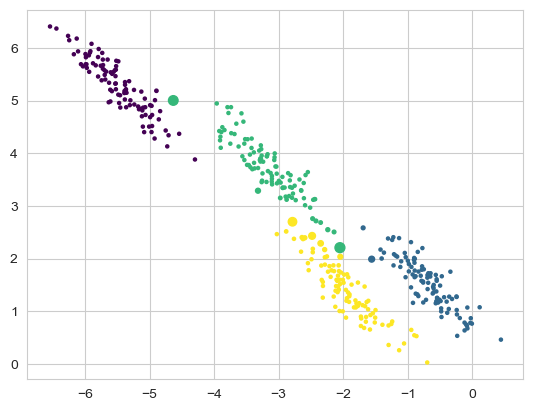

In [ ]:
plt.scatter(X_stretched[:, 0], X_stretched[:, 1], s=(1-(labels_proba.max(axis=1)))*100+5, c=labels, cmap='viridis');
plt.show()

In [ ]:
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Draw an ellipse with a given position and covariance"""
    ax = ax or plt.gca()

    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        angle = 0
        width, height = 2 * np.sqrt(covariance)

    for nsig in range(1, 4):
        ax.add_patch(
            Ellipse(
                position,
                nsig * width,
                nsig * height,
                angle=angle,   
                **kwargs
            )
        )

def plot_gmm(gmm, X, label=True, ax=None):
    ax = ax or plt.gca()

    labels = gmm.fit(X).predict(X)

    if label:
        ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis', zorder=2)
    else:
        ax.scatter(X[:, 0], X[:, 1], s=40, zorder=2)

    ax.axis('equal')

    w_factor = 0.2 / gmm.weights_.max()
    for pos, covar, w in zip(gmm.means_, gmm.covariances_, gmm.weights_): # I don't understand this
        draw_ellipse(pos, covar, ax=ax, alpha=w * w_factor)



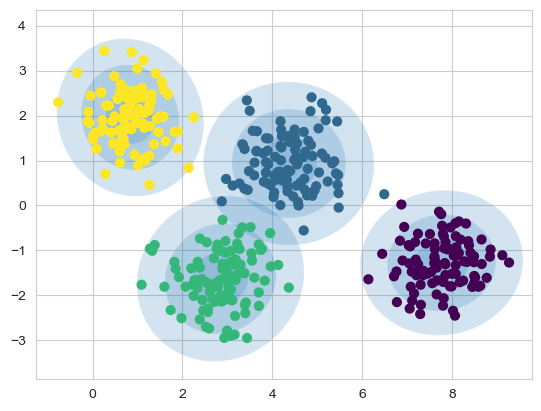

In [ ]:
gmm = GaussianMixture(n_components=4, random_state=0)
plot_gmm(gmm, X)
plt.show()

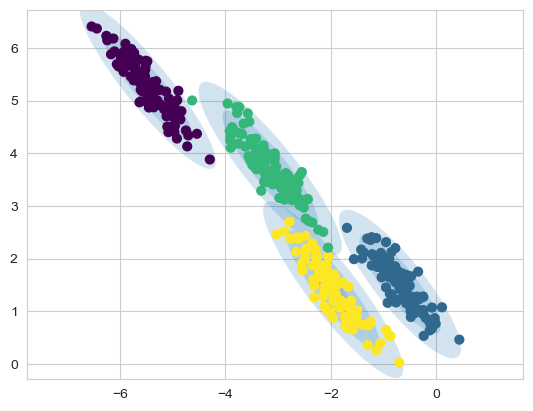

In [ ]:
gmm = GaussianMixture(n_components=4, random_state=0)
plot_gmm(gmm, X_stretched)
plt.show()

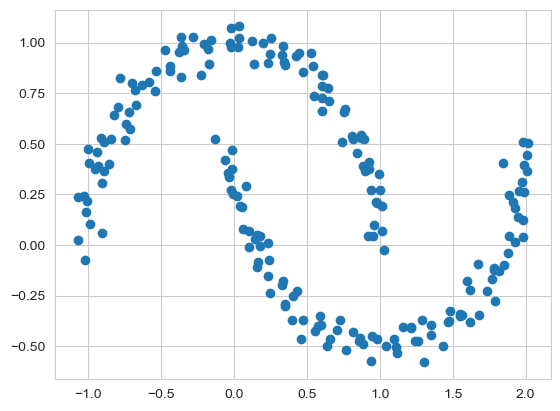

In [ ]:
from sklearn.datasets import make_moons
Xmoon, ymoon = make_moons(200, noise=.05, random_state=0)

plt.scatter(Xmoon[:, 0], Xmoon[:, 1])
plt.show()

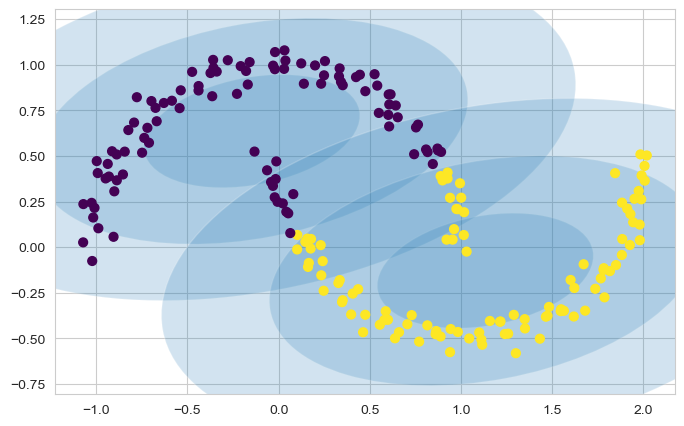

In [ ]:
gmm2 = GaussianMixture(n_components=2, covariance_type='full', random_state=0)

plt.figure(figsize=(8, 5))
plot_gmm(gmm2, Xmoon)
plt.show()

In [ ]:
# Not really, GMM can capture embedded clusters

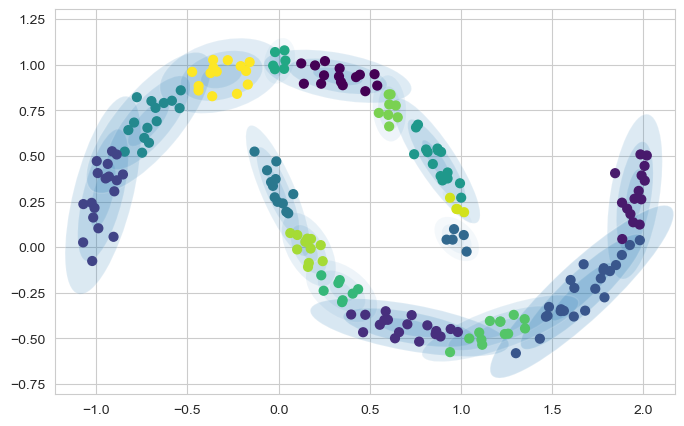

In [ ]:
gmm16 = GaussianMixture(n_components=16, covariance_type='full', random_state=0)

plt.figure(figsize=(8, 5))
plot_gmm(gmm16, Xmoon)
plt.show()

In [ ]:
# A bunch of clusters can capture embedded clusters. Now we have to determine what super group of clusters to form the final two clusters.

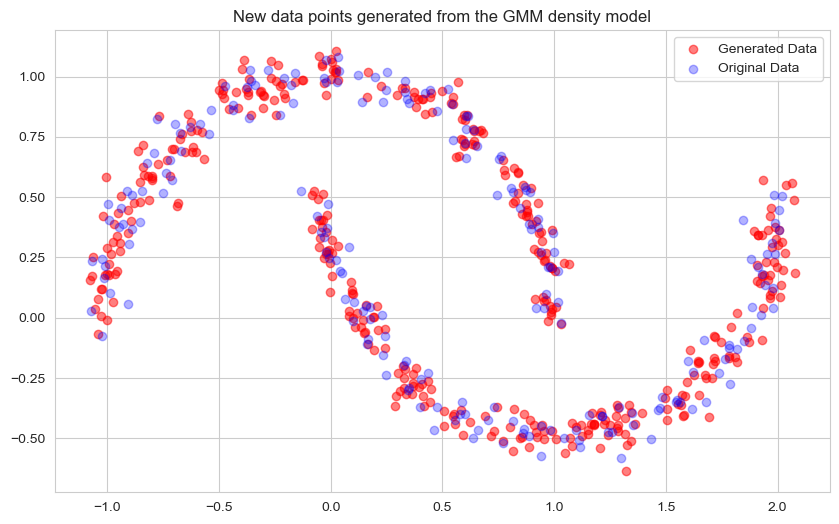

In [ ]:
Xnew, ynew = gmm16.sample(400)

plt.figure(figsize=(10, 6))
plt.scatter(Xnew[:, 0], Xnew[:, 1], alpha=0.5, color='red', label='Generated Data')
plt.scatter(Xmoon[:, 0], Xmoon[:, 1], alpha=0.3, color='blue', label='Original Data')
plt.legend()
plt.title("New data points generated from the GMM density model")
plt.show()

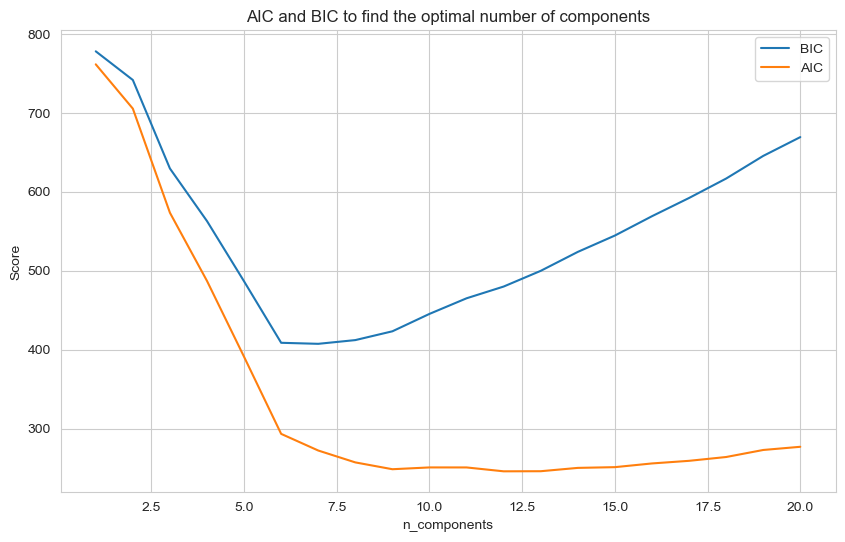

In [ ]:
n_components = np.arange(1, 21)
models = [GaussianMixture(n, covariance_type='full', random_state=0).fit(Xmoon)
          for n in n_components]

plt.figure(figsize=(10, 6))
plt.plot(n_components, [m.bic(Xmoon) for m in models], label='BIC')
plt.plot(n_components, [m.aic(Xmoon) for m in models], label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.ylabel('Score')
plt.title("AIC and BIC to find the optimal number of components")
plt.show()

In [ ]:
'''Thanks to the elbow method we can see that the optimal number of components is 6.'''

'Thanks to the elbow method we can see that the optimal number of components is 6.'

<h3>Part 2:</h3>

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()
print(f"Data shape: {digits.data.shape}")

Data shape: (1797, 64)


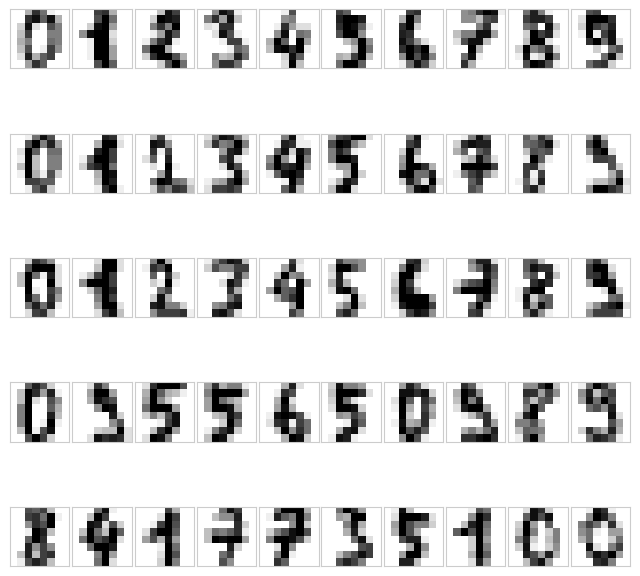

In [ ]:
def plot_digits(data):
    fig, ax = plt.subplots(5, 10, figsize=(8, 8),
                           subplot_kw=dict(xticks=[], yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for i, axi in enumerate(ax.flat):
        im = axi.imshow(data[i].reshape(8, 8), cmap='binary')
        im.set_clim(0, 16)
        
plot_digits(digits.data)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(0.99, whiten=True)
data = pca.fit_transform(digits.data)
print(f"Reduced shape: {data.shape}") 

Reduced shape: (1797, 41)


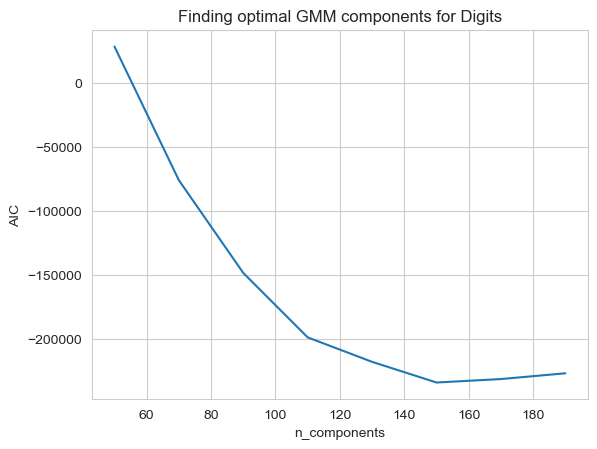

In [ ]:
n_components = np.arange(50, 210, 20)
models = [GaussianMixture(n, covariance_type='full', random_state=0)
          for n in n_components]
aics = [model.fit(data).aic(data) for model in models]

plt.plot(n_components, aics)
plt.xlabel('n_components')
plt.ylabel('AIC')
plt.title("Finding optimal GMM components for Digits")
plt.show()

In [ ]:
gmm = GaussianMixture(150, covariance_type='full', random_state=0)
gmm.fit(data)
print(f"Model converged: {gmm.converged_}")

Model converged: True


In [ ]:
data_new, y_new = gmm.sample(100)

Reconstructed data shape: (100, 64)


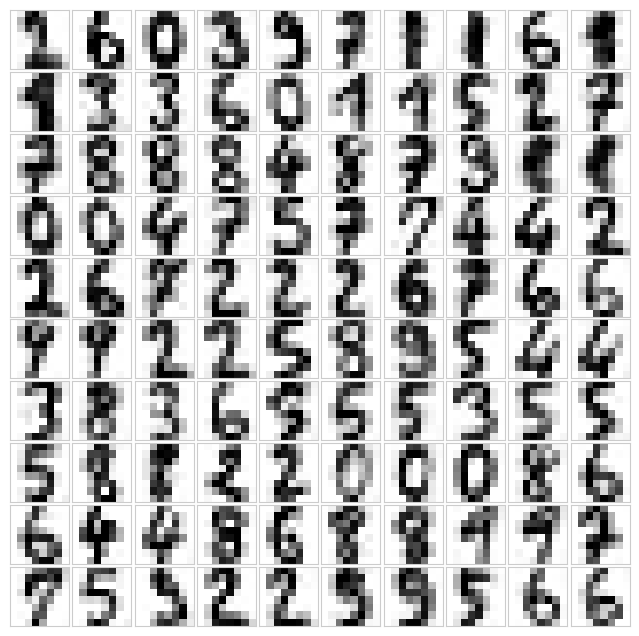

In [ ]:
digits_new = pca.inverse_transform(data_new)
print(f"Reconstructed data shape: {digits_new.shape}")
def plot_digits(data):
    fig, ax = plt.subplots(10, 10, figsize=(8, 8),
                           subplot_kw=dict(xticks=[], yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for i, axi in enumerate(ax.flat):
        im = axi.imshow(data[i].reshape(8, 8), cmap='binary')
        im.set_clim(0, 16)

plot_digits(digits_new)
plt.show()

In [ ]:
# Some generated data are too fuzzy and not even recognizable by human.

<h3>Part 3:</h3>

Shape: (5500, 40)
PCA shape: (5500, 2)


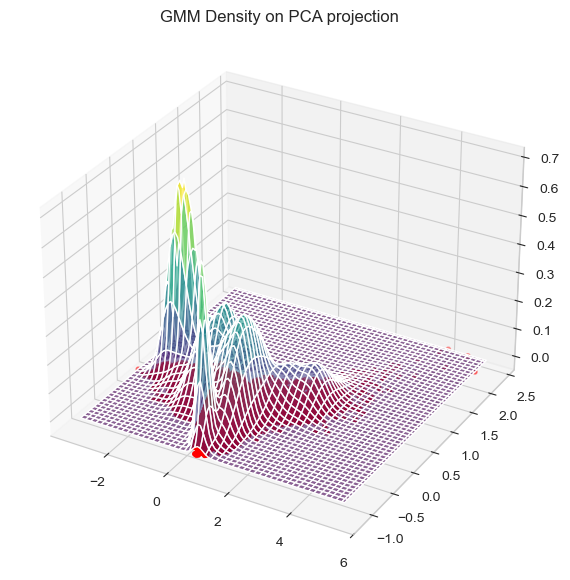

In [ ]:
from sklearn.datasets import fetch_openml
import pandas as pd

textures = fetch_openml(name='texture', version=1, as_frame=False)
#textures = pd.read_csv("texture.txt")
#X_tex = textures[textures.columns[:-1]].values
#y_tex = textures[textures.columns[-1]].values

X_tex = textures.data
y_tex = textures.target

print("Shape:", X_tex.shape)
from sklearn.decomposition import PCA

X_40 = X_tex[:, :40]

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_40)

print("PCA shape:", X_pca.shape)
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=11, covariance_type='full', random_state=0)
gmm.fit(X_pca)
import numpy as np

x = np.linspace(X_pca[:, 0].min(), X_pca[:, 0].max(), 100)
y = np.linspace(X_pca[:, 1].min(), X_pca[:, 1].max(), 100)
X_grid, Y_grid = np.meshgrid(x, y)

grid = np.column_stack([X_grid.ravel(), Y_grid.ravel()])
Z = np.exp(gmm.score_samples(grid))
Z = Z.reshape(X_grid.shape)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_grid, Y_grid, Z, cmap='viridis', alpha=0.6)
ax.scatter(X_pca[:, 0], X_pca[:, 1], np.zeros_like(X_pca[:, 0]),
c='red', s=10)

ax.set_title("GMM Density on PCA projection")
plt.show()

LDA shape: (5500, 2)


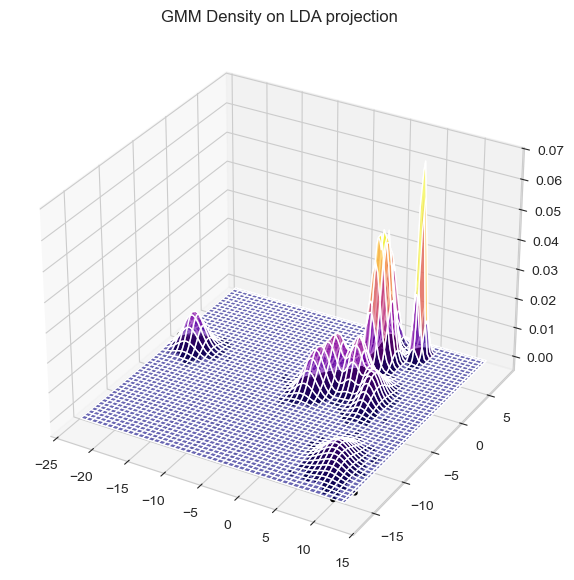

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_40, y_tex)

print("LDA shape:", X_lda.shape)
gmm_lda = GaussianMixture(n_components=11, covariance_type='full', random_state=0)
gmm_lda.fit(X_lda)
x = np.linspace(X_lda[:, 0].min(), X_lda[:, 0].max(), 100)
y = np.linspace(X_lda[:, 1].min(), X_lda[:, 1].max(), 100)
X_grid, Y_grid = np.meshgrid(x, y) # I don't precisely understand this line

grid = np.column_stack([X_grid.ravel(), Y_grid.ravel()])
Z = np.exp(gmm_lda.score_samples(grid))
Z = Z.reshape(X_grid.shape)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_grid, Y_grid, Z, cmap='plasma', alpha=0.6)
ax.scatter(X_lda[:, 0], X_lda[:, 1], np.zeros_like(X_lda[:, 0]),
c='black', s=10)

ax.set_title("GMM Density on LDA projection")
plt.show()

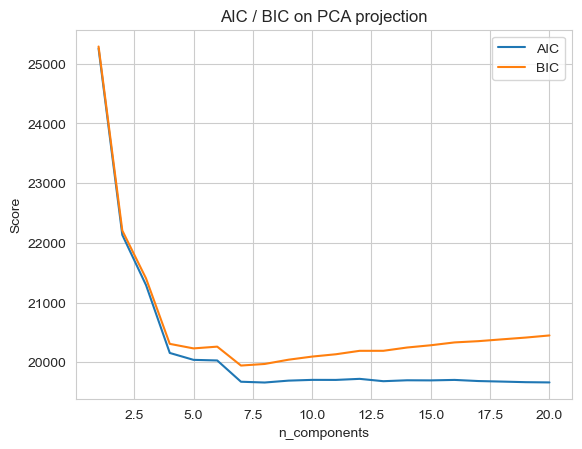

In [ ]:
n_components = np.arange(1, 21)

models = [GaussianMixture(n, covariance_type='full', random_state=0).fit(X_pca)
for n in n_components]

aic = [m.aic(X_pca) for m in models]
bic = [m.bic(X_pca) for m in models]

plt.plot(n_components, aic, label='AIC')
plt.plot(n_components, bic, label='BIC')
plt.xlabel("n_components")
plt.ylabel("Score")
plt.legend()
plt.title("AIC / BIC on PCA projection")
plt.show()

In [ ]:
"""
BIC penalizes model complexity more strongly than AIC.

Even though there are 11 true classes, the projection onto only 2 PCA dimensions
loses information. As a result, some classes overlap or become indistinguishable
in this reduced space.

Therefore, fewer Gaussian components are sufficient to model the density, and BIC
prefers a simpler model to avoid overfitting.
"""

'\nBIC penalizes model complexity more strongly than AIC.\n\nEven though there are 11 true classes, the projection onto only 2 PCA dimensions\nloses information. As a result, some classes overlap or become indistinguishable\nin this reduced space.\n\nTherefore, fewer Gaussian components are sufficient to model the density, and BIC\nprefers a simpler model to avoid overfitting.\n'

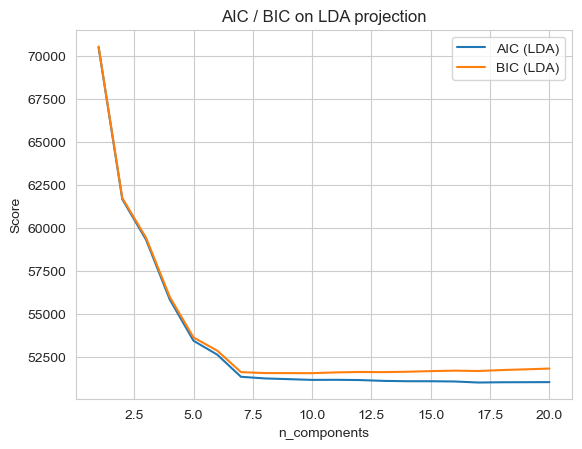

In [ ]:
models_lda = [GaussianMixture(n, covariance_type='full', random_state=0).fit(X_lda)
for n in n_components]

aic_lda = [m.aic(X_lda) for m in models_lda]
bic_lda = [m.bic(X_lda) for m in models_lda]

plt.plot(n_components, aic_lda, label='AIC (LDA)')
plt.plot(n_components, bic_lda, label='BIC (LDA)')
plt.xlabel("n_components")
plt.ylabel("Score")
plt.legend()
plt.title("AIC / BIC on LDA projection")
plt.show()

In [ ]:
"""
With LDA, the projection is supervised and maximizes class separability.

This means the classes are better separated than in PCA, so the GMM can more
accurately model each class individually.

As a result, the optimal number of components is closer to the true number
of classes (11), unlike PCA where information loss caused overlap.
"""

'\nWith LDA, the projection is supervised and maximizes class separability.\n\nThis means the classes are better separated than in PCA, so the GMM can more\naccurately model each class individually.\n\nAs a result, the optimal number of components is closer to the true number\nof classes (11), unlike PCA where information loss caused overlap.\n'